C:\Users\lynda\AppData\Local\Temp\ipykernel_31888\1013579371.py:202: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha='center', fontsize=12, fontweight='bold')


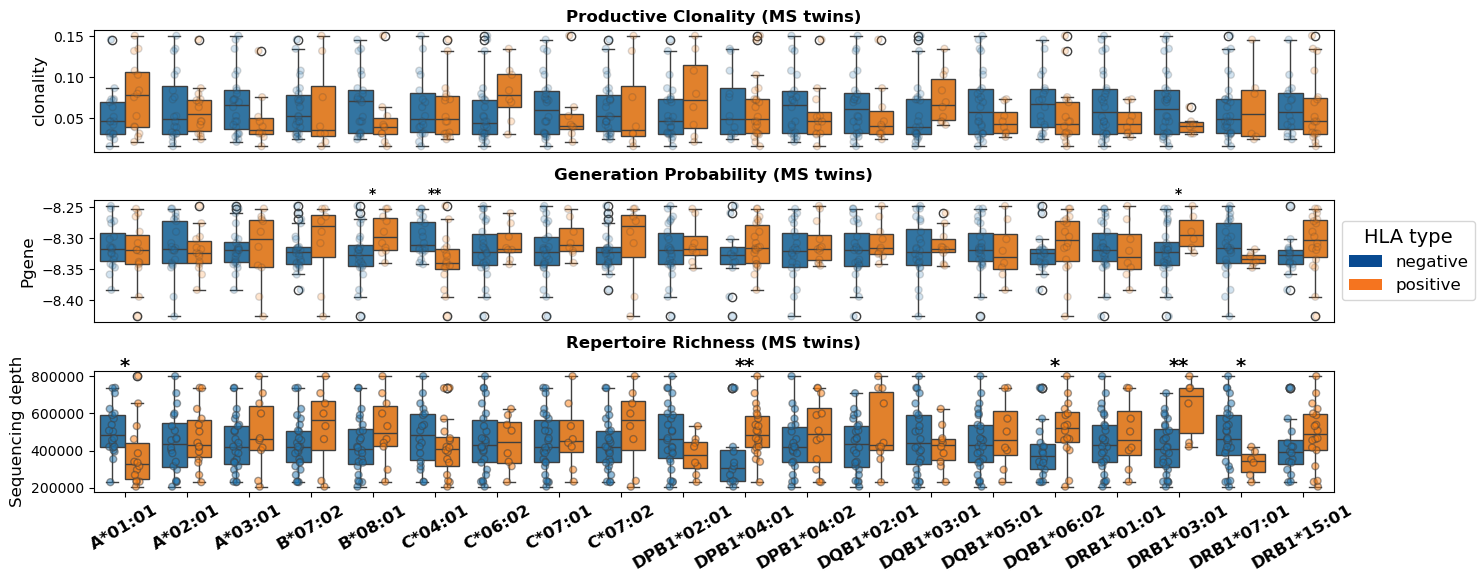

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

import seaborn as sns
import matplotlib.pyplot as plt

top_hla = pd.read_csv('F:/backup_E/meta_data/top_hlas.tsv', sep='\t')
hla_list = top_hla.HLA.values.tolist()
hla_list = sorted(hla_list)

hla_df = pd.read_csv('F:/backup_E/meta_data/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id'] + hla_list]
subject_list = hla_df.subject_id.values.tolist()

df = pd.read_csv('F:/backup_E/2025/01_21_HLA_DRB115/repertoire/clonality/original/twins.csv', sep=',')
df = df.merge(hla_df, on='subject_id')

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


new_df = pd.DataFrame()
for hla in hla_list:
    col = hla.split('_')[1]
    sub_df = df[['subject_id', 'clonality', hla]]
    # sub_df[hla] = sub_df[hla].map({1: 'pos', 0: 'neg'})
    
    pos_df = sub_df[sub_df[hla] == 1]
    neg_df = sub_df[sub_df[hla] == 0]

    statistic, p_value = mannwhitneyu(pos_df['clonality'], neg_df['clonality'])
    star = convert_pvalue_to_asterisks(p_value)

    model = ({
            f'{col}': [p_value, star]
            # 'group': ['positive', 'negative']
            })

    model_df = pd.DataFrame(model)
    new_df = pd.concat([new_df, model_df], axis=1)
new_df.insert(0, 'group', ['p_value', 'significance'])
new_df = new_df.set_index('group')
data = new_df.iloc[:2, :].apply(pd.to_numeric, errors='coerce')
clonality_sign = new_df.loc['significance'].values.tolist()

hla_cols = [c for c in df.columns if c.startswith("HLA_")]

clonality = df.melt(
    id_vars=["subject_id", "MS_status", "clonality"],
    value_vars=hla_cols,
    var_name="HLA_type",
    value_name="present"
)
clonality['HLA_type'] = clonality.HLA_type.apply(lambda x: x.split('_')[1])

## generation probablity

rslt_df = pd.DataFrame()
for subject in subject_list:
    
    df = pd.read_csv(f'F:/backup_E/2025/02_05_genetics/generation_probability/gpro_twins/{subject}.csv', sep='\t')
    mean_value = df.pgen_cdr3_b_aa.mean()
    log_mean = np.log10(mean_value)
    
    new_df = pd.DataFrame({'subject_id': [subject], 'genp': [log_mean]})
    rslt_df = pd.concat([rslt_df, new_df], ignore_index=True, sort=False)
rslt_df = rslt_df.merge(hla_df, on='subject_id')

new_df3 = pd.DataFrame()
for hla in hla_list:
    col = hla.split('_')[1]
    sub_df = rslt_df[['subject_id', 'genp', hla]]
    # sub_df[hla] = sub_df[hla].map({1: 'pos', 0: 'neg'})
    
    pos_df = sub_df[sub_df[hla] == 1]
    neg_df = sub_df[sub_df[hla] == 0]

    statistic, p_value = mannwhitneyu(pos_df['genp'], neg_df['genp'])
    star = convert_pvalue_to_asterisks(p_value)

    model = ({
            f'{col}': [p_value, star]
            # 'group': ['positive', 'negative']
            })

    model_df = pd.DataFrame(model)
    new_df3 = pd.concat([new_df3, model_df], axis=1)
new_df3.insert(0, 'group', ['p_value', 'significance'])
new_df3 = new_df3.set_index('group')
data = new_df3.iloc[:2, :].apply(pd.to_numeric, errors='coerce')
pgen_sign = new_df3.loc['significance'].values.tolist()

hla_cols = [c for c in rslt_df.columns if c.startswith("HLA_")]

pgen = rslt_df.melt(
    id_vars=["subject_id", "genp"],
    value_vars=hla_cols,
    var_name="HLA_type",
    value_name="present"
)
pgen['HLA_type'] = pgen.HLA_type.apply(lambda x: x.split('_')[1])

## richness

df = pd.read_csv('F:/backup_E/2025/02_05_genetics/repertoire_richness/seqs_depth/twins.tsv', sep='\t')
df = df.merge(hla_df, on='subject_id')

new_df = pd.DataFrame()
for hla in hla_list:
    col = hla.split('_')[1]
    sub_df = df[['subject_id', 'seqs_depth', hla]]
    # sub_df[hla] = sub_df[hla].map({1: 'pos', 0: 'neg'})
    
    pos_df = sub_df[sub_df[hla] == 1]
    neg_df = sub_df[sub_df[hla] == 0]

    statistic, p_value = mannwhitneyu(pos_df['seqs_depth'], neg_df['seqs_depth'])
    star = convert_pvalue_to_asterisks(p_value)

    model = ({
            f'{col}': [p_value, star]
            # 'group': ['positive', 'negative']
            })

    model_df = pd.DataFrame(model)
    new_df = pd.concat([new_df, model_df], axis=1)
new_df.insert(0, 'group', ['p_value', 'significance'])
new_df = new_df.set_index('group')
data = new_df.iloc[:2, :].apply(pd.to_numeric, errors='coerce')
richness_sign = new_df.loc['significance'].values.tolist()

hla_cols = [c for c in df.columns if c.startswith("HLA_")]

richness = df.melt(
    id_vars=["subject_id", "seqs_depth"],
    value_vars=hla_cols,
    var_name="HLA_type",
    value_name="present"
)
richness['HLA_type'] = richness.HLA_type.apply(lambda x: x.split('_')[1])

## plots

import matplotlib.patches as mpatches

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 6))
plt.subplots_adjust(hspace=0.4, wspace=0.6)

ax1 = sns.boxplot(data=clonality, x="HLA_type", y="clonality", hue="present", legend=False, ax = axs[0], palette='tab10', )
ax1 = sns.stripplot(data=clonality, x="HLA_type", y="clonality", hue="present", ax = axs[0], palette='tab10',
              dodge=True, alpha=0.2, linewidth=1, legend=False)

for i, (col, star) in enumerate(zip(data.columns, clonality_sign)):
    if star != 'ns':
    
        ax1.text(i, 0.16, star,
                 ha='center', va='bottom',
                 fontsize=10, color='black', weight="bold",
                 zorder=10)

ax1.set_xticks([])
ax1.set_xlabel("")
ax1.set_ylabel("clonality", fontsize=12)
ax1.set_title("Productive Clonality (MS twins)", fontsize=12, x=0.5, y=1.0, fontweight='bold')


# --- middel HEATMAP ---
ax2 = sns.boxplot(data=pgen, x="HLA_type", y="genp", hue="present", legend=False, palette='tab10', ax = axs[1])
ax2 = sns.stripplot(data=pgen, x="HLA_type", y="genp", hue="present", ax = axs[1],palette='tab10', 
              dodge=True, alpha=0.2, linewidth=1, legend=False)

for (i, col), star in zip(enumerate(data.columns), pgen_sign):
    if star != 'ns':
        ax2.text(i, -8.24, star, ha='center', va='bottom', rotation=0,
                 fontsize=10, color='black', weight="bold")
        
ax2.set_title("Generation Probability (MS twins)", fontsize=12, x=0.5, y=1.1, fontweight='bold')
ax2.set_ylabel("Pgene", fontsize=12)
ax2.set_xticks([])
ax2.set_xlabel("")

## ---- bottom heatmap ----
ax3 = sns.boxplot(data=richness, x="HLA_type", y="seqs_depth", hue="present", legend=False, palette='tab10', ax=axs[2])
ax3 = sns.stripplot(data=richness, x="HLA_type", y="seqs_depth", hue="present", ax=axs[2], palette='tab10', 
              dodge=True, alpha=0.5, linewidth=1, legend=False)

for (i, col), star in zip(enumerate(data.columns), richness_sign):
    if star != 'ns':
        ax3.text(i, 800000, star, ha='center', va='bottom', rotation=0,
                 fontsize=14, color='black', weight="bold")
        
ax3.set_title("Repertoire Richness (MS twins)", fontsize=12, x=0.5, y=1.12, fontweight='bold')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha='center', fontsize=12, fontweight='bold')
# ax3.set_xlabel('HLA alleles', fontsize=14)
ax3.set_ylabel("Sequencing depth", fontsize=12)
ax3.set_xlabel("")

handles = [mpatches.Patch(facecolor=plt.cm.Blues(230), label="negative"),
            mpatches.Patch(facecolor=plt.cm.Oranges(150), label="positive")]
legend_properties = {'weight':'bold'}
# plt.set(xlabel=None)
plt.legend(title="HLA type", handles=handles, bbox_to_anchor=(1, 2.3), loc='upper left', 
           title_fontproperties={'size': '14'}, fontsize=12) # prop=legend_properties
plt.show()
plt.close()

In [3]:
fig.savefig('myimage1.png', format='png', dpi=600, bbox_inches='tight')

## validation

In [5]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

import seaborn as sns
import matplotlib.pyplot as plt


def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


top_hla = pd.read_csv('F:/backup_E/meta_data_new_db/top_hlas.tsv', sep='\t')
hla_list = top_hla.HLA.values.tolist()
hla_list = sorted(hla_list)

ms_datasets = ['ms02']
hd_datasets = ['microhd']

# top_hla = pd.read_csv('F:/backup_E/meta_data/top_hlas.tsv', sep='\t')
# hla_list = top_hla.HLA.values.tolist()
hla_df = pd.DataFrame()
for dataset in ms_datasets + hd_datasets:
    hla_df1 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{dataset}_hla_typing.tsv', sep='\t')
    hla_df = pd.concat([hla_df,hla_df1], ignore_index=True, sort=False)
hla_df = hla_df[['subject_id'] + hla_list]

subject_df = pd.read_csv(f'../subject_list/ms02_microhd.tsv', sep='\t')
subject_list = subject_df.subject_id.values.tolist()

ms_df = pd.read_csv(f'../../2025/01_21_HLA_DRB115/repertoire/clonality/original/ms02.csv', sep='\t')
hd_df = pd.read_csv(f'../../2025/01_21_HLA_DRB115/repertoire/clonality/original/microhd.csv', sep='\t')

df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
df = df[df['subject_id'].isin(subject_list)]
df = df.merge(hla_df, on='subject_id')
# df = df[['subject_id', 'clonality', 'HLA_DRB1*11']]

new_df2 = pd.DataFrame()
for hla in hla_list:
    col = hla.split('_')[1]
    sub_df = df[['subject_id', 'clonality', hla]]
    # sub_df[hla] = sub_df[hla].map({1: 'pos', 0: 'neg'})
    
    pos_df = sub_df[sub_df[hla] == 1]
    neg_df = sub_df[sub_df[hla] == 0]

    statistic, p_value = mannwhitneyu(pos_df['clonality'], neg_df['clonality'])
    star = convert_pvalue_to_asterisks(p_value)

    model = ({
            f'{col}': [p_value, star]
            # 'group': ['positive', 'negative']
            })

    model_df = pd.DataFrame(model)
    new_df2 = pd.concat([new_df2, model_df], axis=1)
new_df2.insert(0, 'group', ['p_value', 'significance'])
new_df2 = new_df2.set_index('group')
data = new_df2.iloc[:2, :].apply(pd.to_numeric, errors='coerce')
clonality_sign = new_df2.loc['significance'].values.tolist()

hla_cols = [c for c in df.columns if c.startswith("HLA_")]

clonality = df.melt(
    id_vars=["subject_id", "clonality"],
    value_vars=hla_cols,
    var_name="HLA_type",
    value_name="present"
)
clonality['HLA_type'] = clonality.HLA_type.apply(lambda x: x.split('_')[1])

## generation probability

import os

files = [x[2] for x in os.walk('../../2025/02_05_genetics/generation_probability/gpro_valid/')][0]

from scipy.stats import mannwhitneyu
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

rslt_df = pd.DataFrame()
for file in files:

    df = pd.read_csv(f'../../2025/02_05_genetics/generation_probability/gpro_valid/{file}', sep='\t')
    mean_value = df.pgen_cdr3_b_aa.mean()
    log_mean = np.log10(mean_value)
    
    new_df = pd.DataFrame({'subject_id': [file.split('.')[0]], 'genp': [log_mean]})
    rslt_df = pd.concat([rslt_df, new_df], ignore_index=True, sort=False)
rslt_df = rslt_df.merge(hla_df, on='subject_id')

new_df4 = pd.DataFrame()
for hla in hla_list:
    col = hla.split('_')[1]
    sub_df = rslt_df[['subject_id', 'genp', hla]]
    # sub_df[hla] = sub_df[hla].map({1: 'pos', 0: 'neg'})
    
    pos_df = sub_df[sub_df[hla] == 1]
    neg_df = sub_df[sub_df[hla] == 0]

    statistic, p_value = mannwhitneyu(pos_df['genp'], neg_df['genp'])
    star = convert_pvalue_to_asterisks(p_value)

    model = ({
            f'{col}': [p_value, star]
            # 'group': ['positive', 'negative']
            })

    model_df = pd.DataFrame(model)
    new_df4 = pd.concat([new_df4, model_df], axis=1)
new_df4.insert(0, 'group', ['p_value', 'significance'])
new_df4 = new_df4.set_index('group')
data = new_df4.iloc[:2, :].apply(pd.to_numeric, errors='coerce')
pgen_sign = new_df4.loc['significance'].values.tolist()

hla_cols = [c for c in rslt_df.columns if c.startswith("HLA_")]

pgen = rslt_df.melt(
    id_vars=["subject_id", "genp"],
    value_vars=hla_cols,
    var_name="HLA_type",
    value_name="present"
)
pgen['HLA_type'] = pgen.HLA_type.apply(lambda x: x.split('_')[1])

## richness

hla_df1 = pd.read_csv('F:/backup_E/meta_data_new_db/ms01_hla_typing.tsv', sep='\t')
hla_df2 = pd.read_csv('F:/backup_E/meta_data_new_db/hd01_hla_typing.tsv', sep='\t')
hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True ,sort=False)
hla_df = hla_df[['subject_id'] + hla_list]

df1 = pd.read_csv('../../2025/02_05_genetics/repertoire_richness/seqs_depth/ms01.tsv', sep='\t')
df2 = pd.read_csv('../../2025/02_05_genetics/repertoire_richness/seqs_depth/hd01.tsv', sep='\t')
df = pd.concat([df1, df2], ignore_index=True, sort=False)
df = df.merge(hla_df, on='subject_id')

new_df2 = pd.DataFrame()
for hla in hla_list:
    col = hla.split('_')[1]
    sub_df = df[['subject_id', 'seqs_depth', hla]]
    # sub_df[hla] = sub_df[hla].map({1: 'pos', 0: 'neg'})
    
    pos_df = sub_df[sub_df[hla] == 1]
    neg_df = sub_df[sub_df[hla] == 0]

    statistic, p_value = mannwhitneyu(pos_df['seqs_depth'], neg_df['seqs_depth'])
    star = convert_pvalue_to_asterisks(p_value)

    model = ({
            f'{col}': [p_value, star]
            # 'group': ['positive', 'negative']
            })

    model_df = pd.DataFrame(model)
    new_df2 = pd.concat([new_df2, model_df], axis=1)
new_df2.insert(0, 'group', ['p_value', 'significance'])
new_df2 = new_df2.set_index('group')
data = new_df2.iloc[:2, :].apply(pd.to_numeric, errors='coerce')
richness_sign = new_df2.loc['significance'].values.tolist()

hla_cols = [c for c in df.columns if c.startswith("HLA_")]

richness = df.melt(
    id_vars=["subject_id", "seqs_depth"],
    value_vars=hla_cols,
    var_name="HLA_type",
    value_name="present"
)
richness['HLA_type'] = richness.HLA_type.apply(lambda x: x.split('_')[1])

C:\Users\lynda\AppData\Local\Temp\ipykernel_39352\3641321037.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha='center', fontsize=12, fontweight='bold')


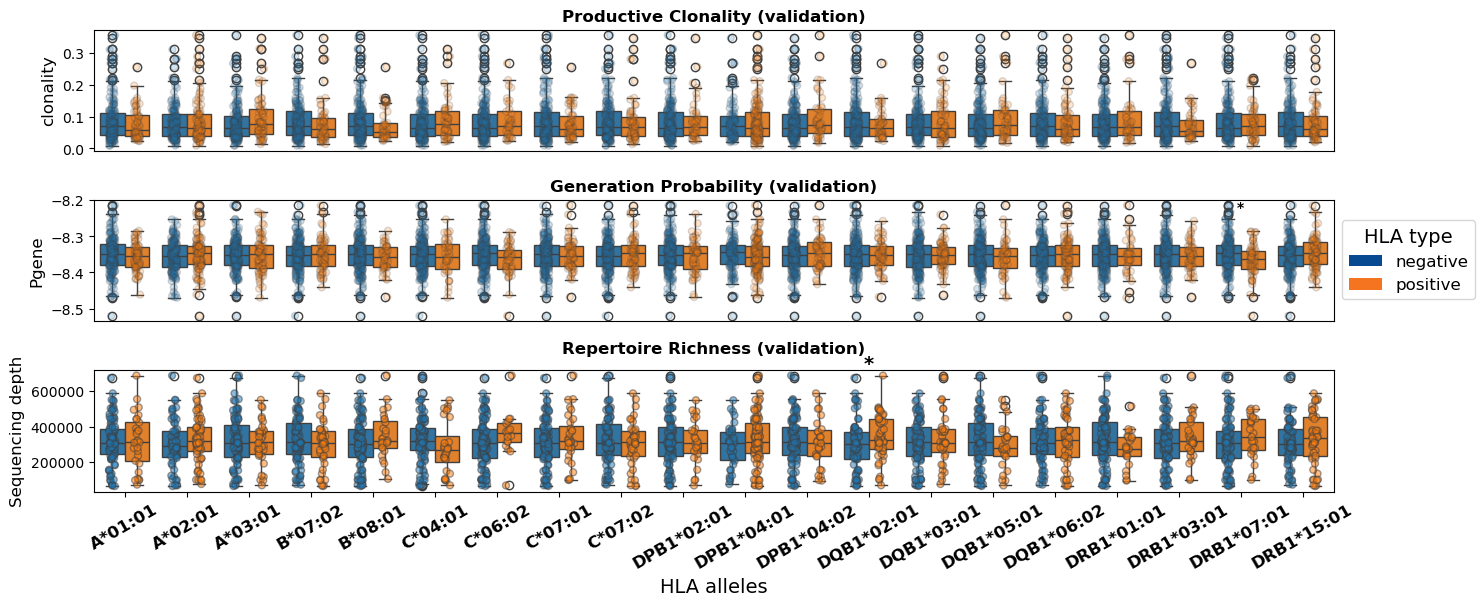

In [6]:
## plots

import matplotlib.patches as mpatches

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 6))
plt.subplots_adjust(hspace=0.4, wspace=0.6)

ax1 = sns.boxplot(data=clonality, x="HLA_type", y="clonality", hue="present", legend=False, ax = axs[0], palette='tab10', )
ax1 = sns.stripplot(data=clonality, x="HLA_type", y="clonality", hue="present", ax = axs[0], palette='tab10',
              dodge=True, alpha=0.2, linewidth=1, legend=False)

for i, (col, star) in enumerate(zip(data.columns, clonality_sign)):
    if star != 'ns':
    
        ax1.text(i, 0.16, star,
                 ha='center', va='bottom',
                 fontsize=10, color='black', weight="bold",
                 zorder=10)

ax1.set_xticks([])
ax1.set_xlabel("")
ax1.set_ylabel("clonality", fontsize=12)
ax1.set_title("Productive Clonality (validation)", fontsize=12, x=0.5, y=1.0, fontweight='bold')


# --- middel HEATMAP ---
ax2 = sns.boxplot(data=pgen, x="HLA_type", y="genp", hue="present", legend=False, palette='tab10', ax = axs[1])
ax2 = sns.stripplot(data=pgen, x="HLA_type", y="genp", hue="present", ax = axs[1],palette='tab10', 
              dodge=True, alpha=0.2, linewidth=1, legend=False)

for (i, col), star in zip(enumerate(data.columns), pgen_sign):
    if star != 'ns':
        ax2.text(i, -8.24, star, ha='center', va='bottom', rotation=0,
                 fontsize=10, color='black', weight="bold")
        
ax2.set_title("Generation Probability (validation)", fontsize=12, x=0.5, y=1, fontweight='bold')
ax2.set_ylabel("Pgene", fontsize=12)
ax2.set_xticks([])
ax2.set_xlabel("")

## ---- bottom heatmap ----
ax3 = sns.boxplot(data=richness, x="HLA_type", y="seqs_depth", hue="present", legend=False, palette='tab10', ax=axs[2])
ax3 = sns.stripplot(data=richness, x="HLA_type", y="seqs_depth", hue="present", ax=axs[2], palette='tab10', 
              dodge=True, alpha=0.5, linewidth=1, legend=False)

for (i, col), star in zip(enumerate(data.columns), richness_sign):
    if star != 'ns':
        ax3.text(i, 700000, star, ha='center', va='bottom', rotation=0,
                 fontsize=14, color='black', weight="bold")
        
ax3.set_title("Repertoire Richness (validation)", fontsize=12, x=0.5, y=1.07, fontweight='bold')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=30, ha='center', fontsize=12, fontweight='bold')
ax3.set_xlabel('HLA alleles', fontsize=14)
ax3.set_ylabel("Sequencing depth", fontsize=12)

handles = [mpatches.Patch(facecolor=plt.cm.Blues(230), label="negative"),
            mpatches.Patch(facecolor=plt.cm.Oranges(150), label="positive")]
legend_properties = {'weight':'bold'}
plt.legend(title="HLA type", handles=handles, bbox_to_anchor=(1, 2.3), loc='upper left', 
           title_fontproperties={'size': '14'}, fontsize=12) # prop=legend_properties
plt.show()
plt.close()

In [7]:
fig.savefig('myimage2.png', format='png', dpi=600, bbox_inches='tight')